# Library

In [ ]:
!pip install optuna catboost scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 386.6/386.6 kB 7.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 MB 9.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 231.9/231.9 kB 13.5 MB/s eta 0:00:00


In [ ]:
!pip install catboost

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


# Dataset

In [ ]:
train = pd.read_csv('/content/drive/MyDrive/train.csv')
test = pd.read_csv('/content/drive/MyDrive/test.csv')
test_ids = test['id']

In [ ]:
train.head()

,id,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,0,No Urgent Place,Friend(s),Sunny,80,6PM,Coffee House,2h,Female,21,...,less1,gt8,1~3,1~3,1,0,0,0,1,0
1,1,Home,Alone,Sunny,80,6PM,Coffee House,2h,Female,50plus,...,never,less1,less1,less1,1,0,0,0,1,0
2,2,Home,Alone,Sunny,55,6PM,Restaurant(20-50),1d,Male,36,...,never,4~8,gt8,less1,1,1,0,0,1,1
3,3,No Urgent Place,Friend(s),Sunny,80,2PM,Restaurant(<20),2h,Male,26,...,gt8,gt8,4~8,less1,1,1,0,0,1,0
4,4,No Urgent Place,Kid(s),Sunny,80,2PM,Restaurant(<20),1d,Male,50plus,...,1~3,4~8,4~8,less1,1,0,0,0,1,1


In [ ]:
test.head()

,id,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,...,Bar,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp
0,0,Home,Alone,Snowy,30,6PM,Coffee House,1d,Female,31,...,less1,less1,gt8,4~8,less1,1,1,0,0,1
1,1,Home,Alone,Sunny,55,6PM,Bar,1d,Female,50plus,...,less1,never,gt8,4~8,1~3,1,0,0,1,0
2,2,No Urgent Place,Alone,Sunny,80,10AM,Coffee House,2h,Female,31,...,never,less1,4~8,1~3,1~3,1,1,0,0,1
3,3,Home,Alone,Sunny,80,6PM,Restaurant(<20),2h,Female,36,...,never,never,1~3,less1,never,1,0,0,1,0
4,4,Home,Alone,Sunny,80,6PM,Coffee House,1d,Male,26,...,less1,less1,1~3,less1,less1,1,0,0,0,1


In [ ]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   id                    4000 non-null   int64 
 1   destination           4000 non-null   object
 2   passanger             4000 non-null   object
 3   weather               4000 non-null   object
 4   temperature           4000 non-null   int64 
 5   time                  4000 non-null   object
 6   coupon                4000 non-null   object
 7   expiration            4000 non-null   object
 8   gender                4000 non-null   object
 9   age                   4000 non-null   object
 10  maritalStatus         4000 non-null   object
 11  has_children          4000 non-null   int64 
 12  education             4000 non-null   object
 13  occupation            4000 non-null   object
 14  income                4000 non-null   object
 15  Bar                   3966 non-null   

In [ ]:
# prompt: tampilkan kolom bertioe int

train.select_dtypes(include=['int64']).columns


Index(['id', 'temperature', 'has_children', 'toCoupon_GEQ5min',
       'toCoupon_GEQ15min', 'toCoupon_GEQ25min', 'direction_same',
       'direction_opp', 'Y'],
      dtype='object')

In [ ]:
train.describe()


,id,temperature,has_children,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
count,4000.000000,4000.000000,4000.000000,4000.0,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,1999.500000,63.293750,0.408000,1.0,0.563250,0.128500,0.217500,0.782500,0.564500
std,1154.844867,19.102321,0.491525,0.0,0.496045,0.334688,0.412597,0.412597,0.495884
min,0.000000,30.000000,0.000000,1.0,0.000000,0.000000,0.000000,0.000000,0.000000
25%,999.750000,55.000000,0.000000,1.0,0.000000,0.000000,0.000000,1.000000,0.000000
50%,1999.500000,80.000000,0.000000,1.0,1.000000,0.000000,0.000000,1.000000,1.000000
75%,2999.250000,80.000000,1.000000,1.0,1.000000,0.000000,0.000000,1.000000,1.000000
max,3999.000000,80.000000,1.000000,1.0,1.000000,1.000000,1.000000,1.000000,1.000000


In [ ]:
Y_counts = train.groupby('Y').Y.count()
print('The number of users that are accepted the coupon is ',Y_counts[1],',',round(Y_counts[1]/train.shape[0]*100,3),'%')
print('The number of users that are rejected the coupon is ',Y_counts[0],',',round(Y_counts[0]/train.shape[0]*100,3),'%')

The number of users that are accepted the coupon is  2258 , 56.45 %
The number of users that are rejected the coupon is  1742 , 43.55 %


# Cleaning

In [ ]:
print("Duplicated rows:", train.duplicated().sum())
missing_count = train.isnull().sum()
missing_percent = missing_count / train.shape[0] * 100
missing_data = pd.DataFrame({'missing_count': missing_count, 'missing_percent': missing_percent})
print(missing_data)

Duplicated rows: 0
                      missing_count  missing_percent
id                                0            0.000
destination                       0            0.000
passanger                         0            0.000
weather                           0            0.000
temperature                       0            0.000
time                              0            0.000
coupon                            0            0.000
expiration                        0            0.000
gender                            0            0.000
age                               0            0.000
maritalStatus                     0            0.000
has_children                      0            0.000
education                         0            0.000
occupation                        0            0.000
income                            0            0.000
Bar                              34            0.850
CoffeeHouse                      55            1.375
CarryAway                  

In [ ]:
# prompt: cek missing values di test

import pandas as pd
missing_count_test = test.isnull().sum()
missing_percent_test = missing_count_test / test.shape[0] * 100
missing_data_test = pd.DataFrame({'missing_count': missing_count_test, 'missing_percent': missing_percent_test})
missing_data_test


,missing_count,missing_percent
id,0,0.0
destination,0,0.0
passanger,0,0.0
weather,0,0.0
temperature,0,0.0
time,0,0.0
coupon,0,0.0
expiration,0,0.0
gender,0,0.0
age,0,0.0


- Drop null value karena presentasenya masih wajar di setiap fiturnya

In [ ]:
train.dropna(inplace=True)


/usr/local/lib/python3.11/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Glyph 128279 (\N{LINK SYMBOL}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


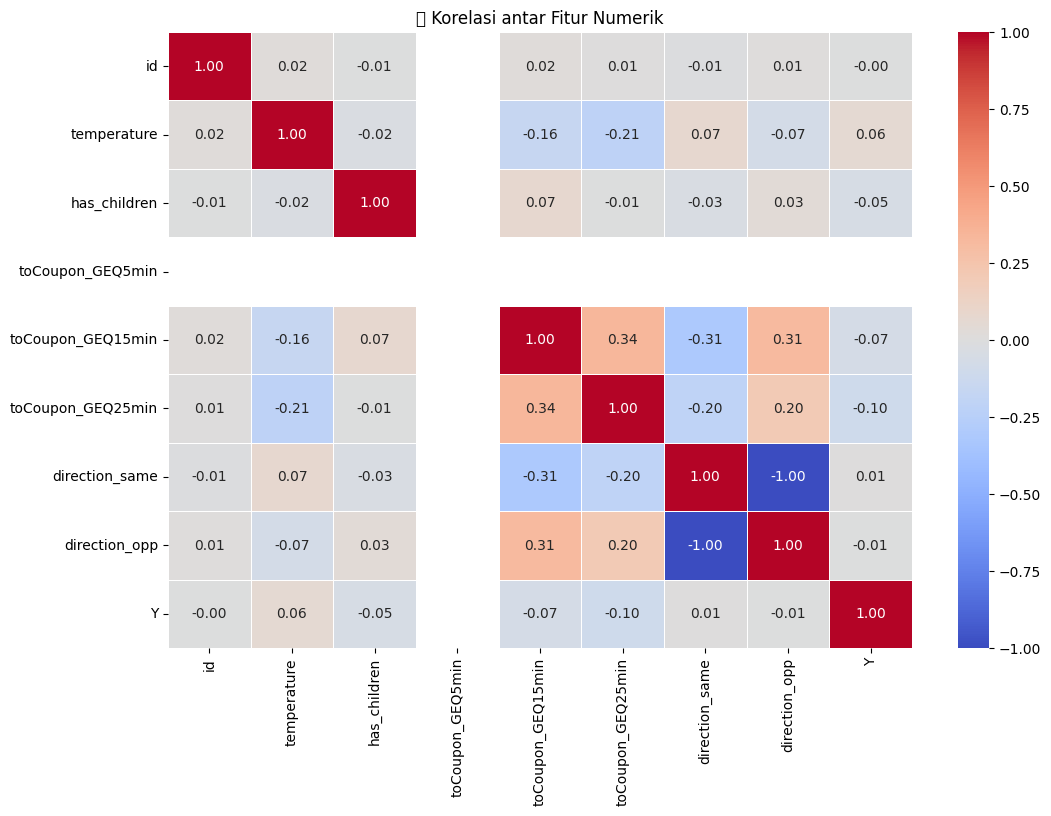

In [ ]:
numeric_cols = train.select_dtypes(include=[np.number])

# Hitung korelasi
corr_matrix = numeric_cols.corr()

# Plot heatmap korelasi
plt.figure(figsize=(12, 8))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', linewidths=0.5)
plt.title('🔗 Korelasi antar Fitur Numerik')
plt.show()

- direction_opp dan direction_same berkorelasi sempurna, maka didrop salah satu untuk mencegah overfitting
- ‘toCoupon_GEQ5min’ tidak berkorelasi dengan fitur manapun sehingga tidak akan mempengaruhi kinerja model maka bisa didrop

In [ ]:
train_drop = train.drop (['direction_same','toCoupon_GEQ5min'], axis=1)
test_drop = test.drop(['direction_same','toCoupon_GEQ5min'], axis=1)

In [ ]:
train_drop.shape

(3805, 24)

- dari correlation matrix direction_opp hanya berkorelasi -0,01 terhadap target Y, maka dilakukan analisis lebih lanjut

In [ ]:
# Analysis of 'direction_opp' feature
df_opp = pd.DataFrame(sorted(list(train_drop['direction_opp'].unique())), columns=['direction_opp'])
df_opp['Total_Count'] = list(train_drop.groupby('direction_opp').Y.count())
df_opp['Total_%'] = round(df_opp['Total_Count'] / train_drop['direction_opp'].shape[0] * 100, 3)
df_opp['Accepted'] = list(train_drop[train_drop.Y == 1].groupby('direction_opp').Y.count())
df_opp['Rejected'] = list(train_drop[train_drop.Y == 0].groupby('direction_opp').Y.count())
df_opp['%Accepted'] = round(df_opp['Accepted'] / df_opp['Total_Count'] * 100, 3)
df_opp['%Rejected'] = round(df_opp['Rejected'] / df_opp['Total_Count'] * 100, 3)

df_opp


,direction_opp,Total_Count,Total_%,Accepted,Rejected,%Accepted,%Rejected
0,0,870,21.75,498,372,57.241,42.759
1,1,3130,78.25,1760,1370,56.230,43.770


- Ratio acceptence dan rejection pada `direction_opp` hampir sama, ada kemungkinan fitur ini tidak akan mempengaruhi performa model. Maka bisa dicoba untuk didrop

In [ ]:
train_drop_dirr = train_drop.drop(['direction_opp'],axis = 1)
train_drop_dirr.shape

(4000, 23)

In [ ]:
test_drop_dirr = test_drop.drop(['direction_opp'],axis  = 1)
test_drop_dirr.shape

(1000, 22)

# Pre-Processing

- Menggabungkan dataset train dan test untuk mempercepat preprocessing

In [ ]:
train_drop_dirr['source'] = 'train'
test_drop_dirr['source'] = 'test'
test_drop_dirr['Y'] = np.nan
df = pd.concat([train_drop_dirr, test_drop_dirr], ignore_index=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 24 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   id                    5000 non-null   int64  
 1   destination           5000 non-null   object 
 2   passanger             5000 non-null   object 
 3   weather               5000 non-null   object 
 4   temperature           5000 non-null   int64  
 5   time                  5000 non-null   object 
 6   coupon                5000 non-null   object 
 7   expiration            5000 non-null   object 
 8   gender                5000 non-null   object 
 9   age                   5000 non-null   object 
 10  maritalStatus         5000 non-null   object 
 11  has_children          5000 non-null   int64  
 12  education             5000 non-null   object 
 13  occupation            5000 non-null   object 
 14  income                5000 non-null   object 
 15  Bar                  

## Modus Imputation for Cateogrical Features

- Mengisi null value pada kolom categorical dengan value yang paling sering muncul (modus)

In [ ]:
for col in ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
cols_to_check = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
print(df[cols_to_check].isnull().sum())


Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
dtype: int64


## Feature Engineering

- Pembuatan fitur `to_Coupon`
Menggabungkan toCoupon_GEQ15min dan toCoupon_GEQ25min menjadi satu fitur kategorikal berisi 0, 1, atau 2 berdasarkan kedekatan pengguna dengan lokasi kupon.

- Pembuatan fitur `coupon_freq`
Mengambil frekuensi kunjungan pengguna ke tempat yang sesuai dengan jenis kupon yang diterima (misalnya Bar, CoffeeHouse), sebagai indikator preferensi.

- Pengelompokan pekerjaan (occupation_class)
Mengklasifikasikan jenis pekerjaan pengguna ke dalam kategori penerimaan kupon: High_Acceptance, Medium_High_Acceptance, dst., untuk menyederhanakan variasi kategori dan meningkatkan generalisasi.

- Penghapusan fitur asli yang sudah diolah
Fitur sumber seperti toCoupon_GEQ15min, Bar, occupation, dll. dihapus karena telah digantikan oleh fitur baru yang lebih informatif dan ringkas.

- Pemilahan fitur kategorikal dan numerik
Fitur-fitur dibagi ke dalam cat_columns dan numeric_columns untuk memudahkan proses encoding dan normalisasi pada tahap preprocessing.



In [ ]:
def create_to_coupon(row):
    if row['toCoupon_GEQ15min'] == 0:
        return 0
    elif row['toCoupon_GEQ15min'] == 1 and row['toCoupon_GEQ25min'] == 0:
        return 1
    else:
        return 2

df['to_Coupon'] = df.apply(create_to_coupon, axis=1)


In [ ]:
def get_coupon_freq(row):
    if row['coupon'] == 'Restaurant(<20)':
        return row['RestaurantLessThan20']
    elif row['coupon'] == 'Coffee House':
        return row['CoffeeHouse']
    elif row['coupon'] == 'Carry out & Take away':
        return row['CarryAway']
    elif row['coupon'] == 'Bar':
        return row['Bar']
    elif row['coupon'] == 'Restaurant(20-50)':
        return row['Restaurant20To50']
    else:
        return np.nan

df['coupon_freq'] = df.apply(get_coupon_freq, axis=1)

In [ ]:
occupation_dict = {
    'Healthcare Support':'High_Acceptance',
    'Construction & Extraction':'High_Acceptance',
    'Healthcare Practitioners & Technical':'High_Acceptance',
    'Protective Service':'High_Acceptance',
    'Architecture & Engineering':'High_Acceptance',
    'Production Occupations':'Medium_High_Acceptance',
    'Student':'Medium_High_Acceptance',
    'Office & Administrative Support':'Medium_High_Acceptance',
    'Transportation & Material Moving':'Medium_High_Acceptance',
    'Building & Grounds Cleaning & Maintenance':'Medium_High_Acceptance',
    'Management':'Medium_Acceptance',
    'Food Preparation & Serving Related':'Medium_Acceptance',
    'Life Physical Social Science':'Medium_Acceptance',
    'Business & Financial':'Medium_Acceptance',
    'Computer & Mathematical':'Medium_Acceptance',
    'Sales & Related':'Medium_Low_Acceptance',
    'Personal Care & Service':'Medium_Low_Acceptance',
    'Unemployed':'Medium_Low_Acceptance',
    'Farming Fishing & Forestry':'Medium_Low_Acceptance',
    'Installation Maintenance & Repair':'Medium_Low_Acceptance',
    'Education&Training&Library':'Low_Acceptance',
    'Arts Design Entertainment Sports & Media':'Low_Acceptance',
    'Community & Social Services':'Low_Acceptance',
    'Legal':'Low_Acceptance',
    'Retired':'Low_Acceptance'
}

df['occupation_class'] = df['occupation'].map(occupation_dict)

In [ ]:
df.drop(columns=[
    'toCoupon_GEQ15min', 'toCoupon_GEQ25min',
    'Bar', 'CoffeeHouse', 'CarryAway',
    'RestaurantLessThan20', 'Restaurant20To50',
    'occupation'
], inplace=True)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                5000 non-null   int64  
 1   destination       5000 non-null   object 
 2   passanger         5000 non-null   object 
 3   weather           5000 non-null   object 
 4   temperature       5000 non-null   int64  
 5   time              5000 non-null   object 
 6   coupon            5000 non-null   object 
 7   expiration        5000 non-null   object 
 8   gender            5000 non-null   object 
 9   age               5000 non-null   object 
 10  maritalStatus     5000 non-null   object 
 11  has_children      5000 non-null   int64  
 12  education         5000 non-null   object 
 13  income            5000 non-null   object 
 14  Y                 4000 non-null   float64
 15  source            5000 non-null   object 
 16  to_Coupon         5000 non-null   int64  


In [ ]:
cat_columns = [
    'destination', 'passanger', 'weather', 'time', 'coupon', 'expiration',
    'gender', 'age', 'maritalStatus', 'education', 'income', 'coupon_freq', 'occupation_class'
]


In [ ]:
numeric_columns = ['temperature', 'has_children', 'to_Coupon']


# Model

- Fungsi `ohe()` digunakan untuk membersihkan dan mengubah fitur kategorikal menjadi representasi biner (one-hot encoding) menggunakan `CountVectorizer`. Fitur numerik dikonversi ke bentuk sparse matrix, fitur (kategorikal & numerik) kemudian digabung menjadi satu variabel X_all dalam format sparse matrix untuk pelatihan model.

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from scipy.sparse import hstack, csr_matrix

def ohe(column_name, X):
    X[column_name] = X[column_name].astype(str)
    X[column_name] = X[column_name].str.replace('~','_')
    X[column_name] = X[column_name].str.replace('[^a-zA-Z0-9_ ]',' ', regex=True)
    X[column_name] = X[column_name].str.replace(' +',' ', regex=True)
    X[column_name] = X[column_name].str.strip()
    X[column_name] = X[column_name].str.replace(' ','_')
    X[column_name] = X[column_name].str.lower()

    vectorizer = CountVectorizer(binary=True)
    X_ohe = vectorizer.fit_transform(X[column_name].values)
    feature_names = [f"{column_name}_{feat}" for feat in vectorizer.get_feature_names_out()]
    return X_ohe, feature_names

# Mulai transformasi
sparse_matrices = []
all_feature_names = []

for col in cat_columns:
    sparse_mat, feat_names = ohe(col, df)
    sparse_matrices.append(sparse_mat)
    all_feature_names.extend(feat_names)

# Numerik jadi sparse
numeric_sparse = csr_matrix(df[numeric_columns].values)
all_feature_names.extend(numeric_columns)
sparse_matrices.append(numeric_sparse)

# Gabungkan semua
X_all = hstack(sparse_matrices).tocsr()


- memisahkan data latih dan data uji berdasarkan kolom 'source':

In [ ]:
train_mask = df['source'] == 'train'
test_mask = df['source'] == 'test'

X_train = X_all[train_mask.to_numpy()]
y_train = df.loc[train_mask, 'Y'].astype(int)

X_test = X_all[test_mask.to_numpy()]
test_ids = df.loc[test_mask, 'id']


## XGBoost

In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import cross_val_score

xgb = XGBClassifier( eval_metric='logloss', n_jobs=-1)
xgb_scores = cross_val_score(xgb, X_train, y_train, scoring='roc_auc', cv=5)
print("XGBoost ROC AUC (CV):", xgb_scores.mean())

xgb.fit(X_train, y_train)


XGBoost ROC AUC (CV): 0.7796470214581432


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=None,
              n_jobs=-1, num_parallel_tree=None, random_state=None, ...)

## SVC

In [ ]:
from sklearn.svm import SVC

svc = SVC(probability=True)
svc_scores = cross_val_score(svc, X_train, y_train, scoring='roc_auc', cv=5)
print("SVC ROC AUC (CV):", svc_scores.mean())

svc.fit(X_train, y_train)


SVC ROC AUC (CV): 0.7229042400125227


SVC(probability=True)

## Catboost

In [ ]:
from catboost import CatBoostClassifier
import pandas as pd


catboost = CatBoostClassifier(verbose=0)

catboost_scores = cross_val_score(catboost, X_train.toarray(), y_train, scoring='roc_auc', cv=5)
print("CatBoost ROC AUC (CV):", catboost_scores.mean())


catboost.fit(X_train.toarray(), y_train)


y_pred_prob = catboost.predict_proba(X_test.toarray())[:, 1]

y_pred_binary = (y_pred_prob > 0.5).astype(int)


submission = pd.DataFrame({
    'id': test_ids,
    'Y': y_pred_binary
})


submission.to_csv('catboost_submission.csv', index=False)

print("Submission file has been created and saved as 'catboost_submission.csv'.")


CatBoost ROC AUC (CV): 0.7957033281715562
Submission file has been created and saved as 'catboost_submission.csv'.


# Model Without Feature Engineering

- Karena model yang dibuat dengan dataset yang sudah diprocessing tidak memberikan hasil yang optimal, maka dilakukan alternatif model lain menggunakan dataset asli tanpa feature engineering
- Model yang dibuat meliputi XGBoost, SVC, Catboost seperti sebelumnya

In [ ]:
train['source'] = 'train'
test['source'] = 'test'
test['Y'] = np.nan
df_2 = pd.concat([train, test], ignore_index=True)

In [ ]:
for col in ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']:
    df_2[col] = df_2[col].fillna(df_2[col].mode()[0])

In [ ]:
cols_to_check = ['Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
print(df_2[cols_to_check].isnull().sum())


Bar                     0
CoffeeHouse             0
CarryAway               0
RestaurantLessThan20    0
Restaurant20To50        0
dtype: int64


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report
from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from scipy.sparse import hstack

# Pastikan Y bertipe numerik
df_2['Y'] = pd.to_numeric(df_2['Y'], errors='coerce')

# Definisikan kolom
cat_columns = [
    'destination', 'passanger', 'weather', 'time', 'coupon', 'expiration',
    'gender', 'age', 'maritalStatus', 'education', 'income', 'occupation',
    'Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50'
]

numeric_columns = [
    'temperature', 'has_children',
    'toCoupon_GEQ5min', 'toCoupon_GEQ15min', 'toCoupon_GEQ25min',
    'direction_same', 'direction_opp'
]

# Pisah train dan test
train_mask = df_2['source'] == 'train'
test_mask = df_2['source'] == 'test'

X = df_2[cat_columns + numeric_columns]
y = df_2['Y']

X_train = X.loc[train_mask]
y_train = y.loc[train_mask].astype(int)
X_test = X.loc[test_mask]

# OneHot Encoding
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=True)
X_cat_train = encoder.fit_transform(X_train[cat_columns])
X_cat_test = encoder.transform(X_test[cat_columns])

# Scaling numerik
scaler = StandardScaler()
X_num_train = scaler.fit_transform(X_train[numeric_columns])
X_num_test = scaler.transform(X_test[numeric_columns])

# Gabungkan
from scipy.sparse import csr_matrix
X_train_all = hstack([X_cat_train, csr_matrix(X_num_train)]).tocsr()
X_test_all = hstack([X_cat_test, csr_matrix(X_num_test)]).tocsr()

In [ ]:
from sklearn.metrics import roc_auc_score

# SVC (menggunakan decision_function karena tidak pakai probability=True)
svc = SVC(kernel='rbf', probability=True)
svc.fit(X_train_all, y_train)
svc_probs = svc.predict_proba(X_train_all)[:, 1]
svc_auc = roc_auc_score(y_train, svc_probs)
print(f"SVC ROC AUC: {svc_auc:.4f}")

# CatBoost
catboost = CatBoostClassifier(verbose=0)
catboost.fit(X_train_all, y_train)
catboost_probs = catboost.predict_proba(X_train_all)[:, 1]
catboost_auc = roc_auc_score(y_train, catboost_probs)
print(f"CatBoost ROC AUC: {catboost_auc:.4f}")

# XGBoost
xgb = XGBClassifier(use_label_encoder=False, eval_metric='logloss')
xgb.fit(X_train_all, y_train)
xgb_probs = xgb.predict_proba(X_train_all)[:, 1]
xgb_auc = roc_auc_score(y_train, xgb_probs)
print(f"XGBoost ROC AUC: {xgb_auc:.4f}")


SVC ROC AUC: 0.9084
CatBoost ROC AUC: 0.9667
XGBoost ROC AUC: 0.9963


## Tuning Catboost

- Untuk mengoptimalkan hasil model catboost dilakukan percobaan menggunakan Catboost tuning dengan optuna

In [ ]:

catboost_preds = catboost.predict_proba(X_test_all)[:, 1]

Catboost_preds_binary = (catboost_preds > 0.5).astype(int)

submission = pd.DataFrame({
    'id': df_2.loc[test_mask, 'id'],
    'Y': Catboost_preds_binary
})


submission.to_csv('submission_catboost.csv', index=False)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from catboost import CatBoostClassifier
import optuna
from scipy.sparse import hstack, csr_matrix
# Fungsi Objective untuk Optuna
def objective(trial):
    # Tentukan ruang pencarian hyperparameter
    params = {
        'iterations': trial.suggest_int('iterations', 100, 500),
        'depth': trial.suggest_int('depth', 4, 10),
        'learning_rate': trial.suggest_loguniform('learning_rate', 1e-3, 0.3),
        'l2_leaf_reg': trial.suggest_loguniform('l2_leaf_reg', 1e-3, 10),
        'random_strength': trial.suggest_uniform('random_strength', 0.0, 10.0),
        'bagging_temperature': trial.suggest_uniform('bagging_temperature', 0.0, 1.0),
        'border_count': trial.suggest_int('border_count', 32, 255)
    }

    # Bagi data training menjadi train dan validasi untuk evaluasi hyperparameter
    X_tr, X_val, y_tr, y_val = train_test_split(X_train_all, y_train, test_size=0.2, random_state=42)

    # Karena CatBoost tidak selalu menerima sparse matrix secara langsung,
    # konversi data ke dense jika diperlukan
    if hasattr(X_tr, "toarray"):
        X_tr_dense = X_tr.toarray()
        X_val_dense = X_val.toarray()
    else:
        X_tr_dense, X_val_dense = X_tr, X_val

    # Buat model CatBoost dengan hyperparameter yang diusulkan
    model = CatBoostClassifier(
        iterations=params['iterations'],
        depth=params['depth'],
        learning_rate=params['learning_rate'],
        l2_leaf_reg=params['l2_leaf_reg'],
        random_strength=params['random_strength'],
        bagging_temperature=params['bagging_temperature'],
        border_count=params['border_count'],
        verbose=0
    )

    model.fit(X_tr_dense, y_tr)
    y_val_pred = model.predict_proba(X_val_dense)[:, 1]
    auc = roc_auc_score(y_val, y_val_pred)
    return auc

# Buat study Optuna untuk memaksimalkan ROC AUC
study = optuna.create_study(direction='maximize')
study.optimize(objective, n_trials=50)

print("Best trial hyperparameters:")
print(study.best_trial.params)
print("Best ROC AUC:", study.best_trial.value)

# Latih model final menggunakan hyperparameter terbaik dan seluruh data training
best_params = study.best_trial.params

# Konversi seluruh X_train_all ke dense
if hasattr(X_train_all, "toarray"):
    X_train_dense = X_train_all.toarray()
else:
    X_train_dense = X_train_all

final_model = CatBoostClassifier(
    iterations=best_params['iterations'],
    depth=best_params['depth'],
    learning_rate=best_params['learning_rate'],
    l2_leaf_reg=best_params['l2_leaf_reg'],
    random_strength=best_params['random_strength'],
    bagging_temperature=best_params['bagging_temperature'],
    border_count=best_params['border_count'],
    verbose=100
)

final_model.fit(X_train_dense, y_train)

# Prediksi pada data test menggunakan model final (konversi ke dense jika perlu)
if hasattr(X_test_all, "toarray"):
    X_test_dense = X_test_all.toarray()
else:
    X_test_dense = X_test_all

# Mendapatkan probabilitas untuk kelas 1
test_preds = final_model.predict_proba(X_test_dense)[:, 1]

# Buat file submission, di mana file submission berisi id dan prediksi probabilitas
submission = pd.DataFrame({
    'id': df_2.loc[test_mask, 'id'],
    'Y': test_preds
})

submission.to_csv('submission_catboost_optuna.csv', index=False)
print("Submission file 'submission_catboost_optuna.csv' telah dibuat.")

[I 2025-05-13 11:57:56,793] A new study created in memory with name: no-name-c3360bd5-6dbc-4d33-a03d-f47c6fbf3bc0
<ipython-input-28-38df89b6f2e9>:15: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'learning_rate': trial.suggest_loguniform('learning_rate', 1e-3, 0.3),
<ipython-input-28-38df89b6f2e9>:16: FutureWarning: suggest_loguniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float(..., log=True) instead.
  'l2_leaf_reg': trial.suggest_loguniform('l2_leaf_reg', 1e-3, 10),
<ipython-input-28-38df89b6f2e9>:17: FutureWarning: suggest_uniform has been deprecated in v3.0.0. This feature will be removed in v6.0.0. See https://github.com/optuna/optuna/releases/tag/v3.0.0. Use suggest_float instead.
  'random_strength': trial.suggest_unifo

Best trial hyperparameters:
{'iterations': 345, 'depth': 10, 'learning_rate': 0.03385808744991343, 'l2_leaf_reg': 3.3285217827180404, 'random_strength': 1.067805109789402, 'bagging_temperature': 0.734879543628174, 'border_count': 146}
Best ROC AUC: 0.8231154361469571
0:	learn: 0.6842594	total: 21.6ms	remaining: 7.42s
100:	learn: 0.3718417	total: 3.52s	remaining: 8.5s
200:	learn: 0.2579569	total: 5.3s	remaining: 3.8s
300:	learn: 0.1847250	total: 7.73s	remaining: 1.13s
344:	learn: 0.1608406	total: 9.11s	remaining: 0us
Submission file 'submission_catboost_optuna.csv' telah dibuat.


# Kesimpulan

- Dari seluruh model yang telah dicoba didapatkan hasil terbaik adalah model menggunakan Catboost dengan dataset tanpa feature engineering akurasi sebesar 0.9667
- Kemudian untuk mengoptimalkan model catboost dilakukan tuning dengan optuna kemudian didaptkan hasil akurasi  0.823